# Permanente evaluatie - vaardigheidstoets 1 (P1)
AP Hogeschool - 2ITAI - ML Algorithms

## Opgave

De dataset vinden jullie in dezelfde map als deze notebook, onder de naam **`winequality-red.csv`**. De dataset bevat informatie over **1599 rode wijnen**: voor elke wijn staat er een reeks fysico-chemische eigenschappen in de dataset, evenals een eindscore voor de kwaliteit.

De kolom **`quality`** is de doelvariabele die jullie moeten voorspellen op basis van de andere kolommen. Bekijk deze doelvariabele op **twee manieren** en bouw voor elk van beide een eigen voorspellingsmodel:

1. **Als een label** – behandel `quality` als een label..
2. **Als een numerieke waarde** – behandel `quality` als een gewone numerieke waarde en probeer die waarde zo goed mogelijk te voorspellen.

Pas voor **elk van deze twee interpretaties** minstens **1 goed onderbouwde modellen** toe op de dataset. Zorg voor de nodige voorbereiding van de data (preprocessing) waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom.** Indien je een random state nodig hebt, gebruik random seed **1**.

### Inleveren:
- Hernoem je bestand naar **P1-2026-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laad dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd. Bedenk dus dat als de dataset groot is, het trainen lang kan duren. Perfectioneer eerst je model op een deel van de dataset.

### Indicatieve puntenverdeling /20
- goede uitwerking van model voor het **label**-model: 4 ptn
- goede uitwerking van model voor het **numeriek**-model: 4 ptn
- goede beschrijving over de keuze van deze modellen: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

### Meer info over de features van deze dataset:

- **fixed acidity** – hoeveelheid vaste (niet-vluchtige) zuren, zoals wijnsteenzuur, in gram per liter
- **volatile acidity** – hoeveelheid vluchtige zuren, waaronder azijnzuur, in gram per liter; een te hoge waarde geeft een onaangename, azijnachtige smaak
- **citric acid** – hoeveelheid citroenzuur in gram per liter
- **residual sugar** – hoeveelheid restsuiker in gram per liter
- **chlorides** – hoeveelheid zout (natriumchloride) in gram per liter
- **free sulfur dioxide** – hoeveelheid vrij zwaveldioxide in mg per liter
- **total sulfur dioxide** – totale hoeveelheid zwaveldioxide in mg per liter
- **density** – dichtheid van de wijn, uitgedrukt in gram per kubieke centimeter
- **pH** – zuurtegraad van de wijn (schaal van 0 tot 14, lager = zuurder)
- **sulphates** – hoeveelheid sulfaten, zoals kaliumsulfaat, in gram per liter
- **alcohol** – alcoholpercentage van de wijn, in volumeprocent
- **quality** – **dit is de doelvariabele**: de eindscore voor de kwaliteit van de wijn, als geheel getal tussen 0 en 10 (in deze dataset liggen de scores tussen 3 en 8)

Veel succes!

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Accuracy: 0.60
Confusion Matrix:
[[  0   0   0   1   0   0]
 [  0   1   8   4   0   0]
 [  0   1 100  36   3   0]
 [  0   0 

/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


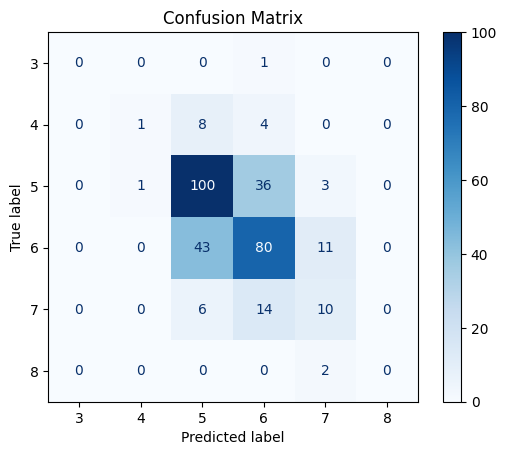

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from matplotlib import pyplot as plt

wine = pd.read_csv("winequality-red.csv")

wine.describe()
# het gaat om een kleine dataset met een kleine hoeveelheid features.
# Eerst ga ik het behandelen als een numerieke waarde en ik kies hiervoor KNN die werkt goed met een kleine dataset en een kleine hoeveelheid features
wine.isnull().sum()
#het heeft geen lege waarden dus ik moet niet gaan imputen
wine.info()
print()
#het zijn allemaal getallen dus ik moet geen waarde gaan omzetten of encoden
#ik haal de juiste data eruit
X = wine.drop(columns=["quality"])
y = wine['quality']
#ik splits het op in test en train data ik gebruik  de gevraagd random state 1 en de test_size dat we meestal in de les gebruiken 0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

#knn moet je gebruikelijk wel scalen dus ik doe dit hier maar ik gebruik ineens een pipeline
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors= 5)) #koos hier voor 5 omdat dat de standaard is, met 1 kan ik een beetje hoger gaan of met 20 maar ik laat het voor nu zo en check het ander model
]) #als ik ietsje meer tijd had, kon ik een gridsearch doen maar ik ben wat bang dat het dan iets te lang gaat duren en dat ik dan geen tijd ga hebben voor de resterende modellen
pipe_knn.fit(X_train,y_train)

knn_pred = pipe_knn.predict(X_test)

accuracy = accuracy_score(y_test, knn_pred)
#hier bereken ik de accuracy van het model
conf_matrix = confusion_matrix(y_test, knn_pred)
#hier bereken ik de confusion matrix van het model
class_report = classification_report(y_test, knn_pred)
#hier bereken ik het classificatie report
print()
print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

#plot confusion matrix KNN
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=pipe_knn.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()





Accuracy: 0.59
Confusion Matrix:
[[  0   0   1   0   0   0]
 [  0   0   8   5   0   0]
 [  0   0 108  20  12   0]
 [  0   0  46  61  27   0]
 [  0   0   3   6  21   0]
 [  0   0   0   0   2   0]]
Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        13
           5       0.65      0.77      0.71       140
           6       0.66      0.46      0.54       134
           7       0.34      0.70      0.46        30
           8       0.00      0.00      0.00         2

    accuracy                           0.59       320
   macro avg       0.28      0.32      0.28       320
weighted avg       0.59      0.59      0.58       320



/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


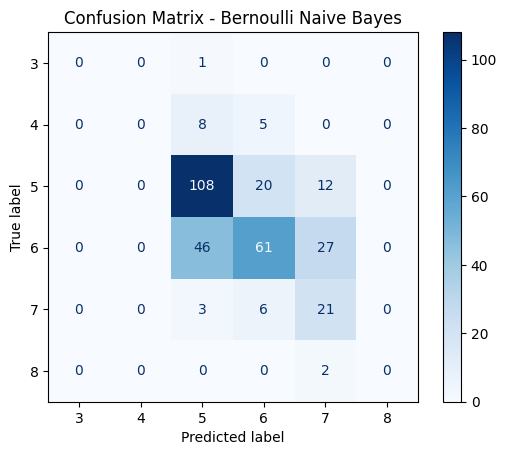

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import BernoulliNB
from matplotlib import pyplot as plt


#omdat het dezelfde dataset is doe ik niet opnieuw alle info() describe() enzo ik weet dit al
#omdat er wordt gevraagd om het te beschouwen als een label, gebruik ik de NaiveBayes

wijn = pd.read_csv('winequality-red.csv')
X_nb,y_nb = wijn.drop(columns=["quality"]),wijn["quality"]
X_train, X_test, y_train, y_test = train_test_split(X_nb, y_nb, test_size=0.2, random_state=1)
#ik maak opnieuw een pipeline
pipe_nb = Pipeline([
    ('scaler',StandardScaler()),
    ('bayes',BernoulliNB())
])
pipe_nb.fit(X_train,y_train)

nb_pred = pipe_nb.predict(X_test)

accuracy_nb = accuracy_score(y_test, nb_pred)
#hier bereken ik de accuracy van het model
conf_matrix_nb = confusion_matrix(y_test, nb_pred)
#hier bereken ik de confusion matrix van het model
class_report_nb = classification_report(y_test, nb_pred)
#hier bereken ik het classificatie report
print()
print(f"Accuracy: {accuracy_nb:.2f}")
print("Confusion Matrix:")
print(conf_matrix_nb)
print("Classification Report:")
print(class_report_nb)

#dit is ietsje slechter dan het vorige model op eerste zicht, op dit punt zou ik bespreken met de klant om te zien of er andere opties zijn en welke van de 
#2 confusion matrices ze beter vinden na het te hebben uitgelegd
#plot confusion matrix Naive Bayes
disp_nb = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_nb, display_labels=pipe_nb.classes_)
disp_nb.plot(cmap='Blues')
plt.title('Confusion Matrix - Bernoulli Naive Bayes')
plt.show()

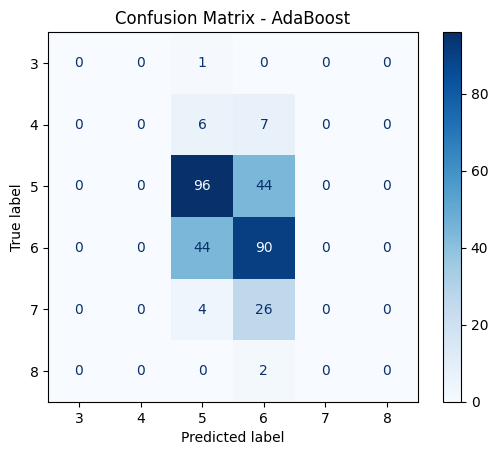


ADABoost Classifier Metrics:
Accuracy: 0.58
Confusion Matrix:
[[ 0  0  1  0  0  0]
 [ 0  0  6  7  0  0]
 [ 0  0 96 44  0  0]
 [ 0  0 44 90  0  0]
 [ 0  0  4 26  0  0]
 [ 0  0  0  2  0  0]]
Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        13
           5       0.64      0.69      0.66       140
           6       0.53      0.67      0.59       134
           7       0.00      0.00      0.00        30
           8       0.00      0.00      0.00         2

    accuracy                           0.58       320
   macro avg       0.19      0.23      0.21       320
weighted avg       0.50      0.58      0.54       320



/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [53]:
#gewoon voor mezelf ga ik het ook eens proberen met Adaboost omdat ik vind dat beide andere modellen een lagere accuracy hebben dan verwacht

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,ConfusionMatrixDisplay
from matplotlib import pyplot as plt
from sklearn.ensemble import AdaBoostClassifier

#ik houd de rest ongeveer hetzelfde


wijn_ada = pd.read_csv('winequality-red.csv')
X_xgb,y_xgb = wijn_ada.drop(columns=["quality"]),wijn_ada["quality"]
X_train, X_test, y_train, y_test = train_test_split(X_xgb, y_xgb, test_size=0.2, random_state=1)
#hier maak ik geen pipeline omdat ada meestal niet gescaled moet worden dus (en moet niet imputen of encoden hier) dus ik doe het rechtstreeks
ada = AdaBoostClassifier(n_estimators=5, learning_rate=1,random_state=1) #ik kies voor 1 omdat dit standaard wordt gebruikt
ada.fit(X_train,y_train)

ada_pred = ada.predict(X_test)
# Plot confusion matrix for AdaBoost
disp_ada = ConfusionMatrixDisplay(confusion_matrix=confusion_ada, display_labels=ada.classes_)
disp_ada.plot(cmap='Blues')
plt.title('Confusion Matrix - AdaBoost')
plt.show()
accuracy_ada = accuracy_score(y_test, ada_pred)
confusion_ada = confusion_matrix(y_test, ada_pred)

print("\nADABoost Classifier Metrics:")
print(f"Accuracy: {accuracy_ada:.2f}")

print("Confusion Matrix:")
print(confusion_ada)
class_report_ada = classification_report(y_test, ada_pred)
print("Classification Report:")
print(class_report_ada)
#ik krijg ongeveer dezelfde accuracy met adaboost 

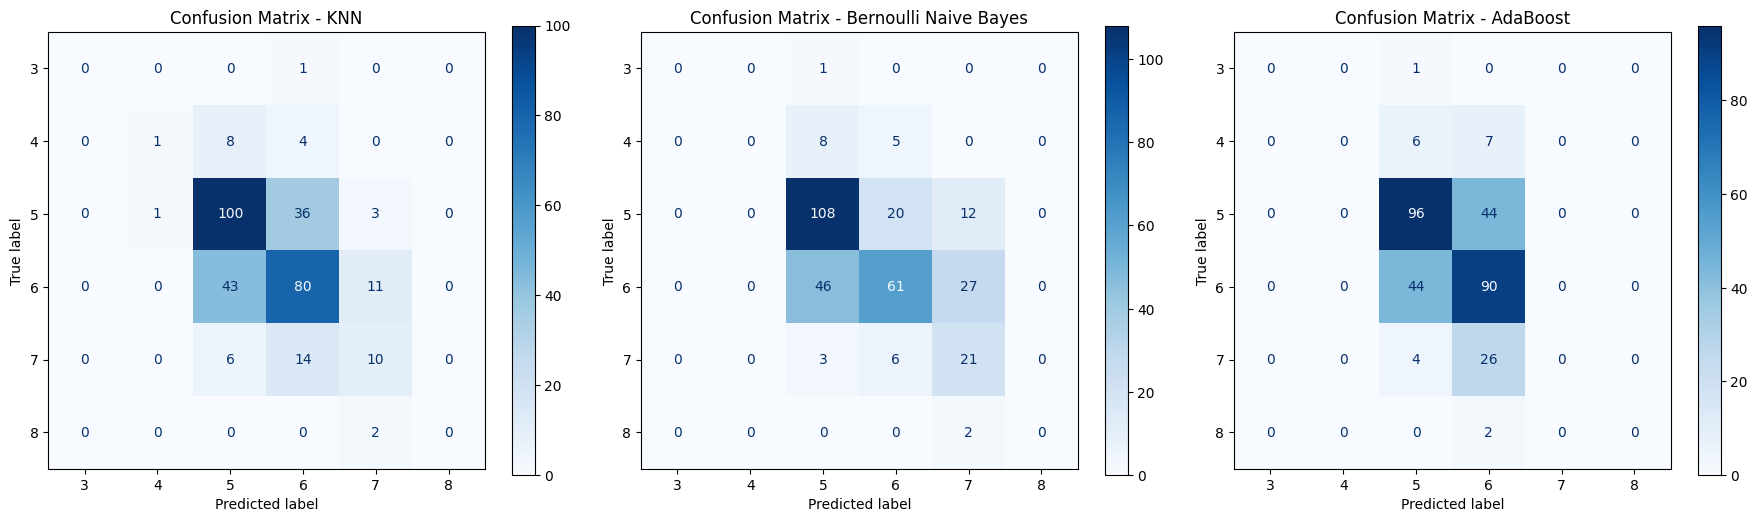

In [54]:
# Plot confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# KNN Confusion Matrix
disp_knn = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=pipe_knn.classes_)
disp_knn.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix - KNN')

# Bernoulli Naive Bayes Confusion Matrix
disp_nb = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_nb, display_labels=pipe_nb.classes_)
disp_nb.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix - Bernoulli Naive Bayes')

# AdaBoost Confusion Matrix
disp_ada = ConfusionMatrixDisplay(confusion_matrix=confusion_ada, display_labels=ada.classes_)
disp_ada.plot(ax=axes[2], cmap='Blues')
axes[2].set_title('Confusion Matrix - AdaBoost')

plt.tight_layout()
plt.show()

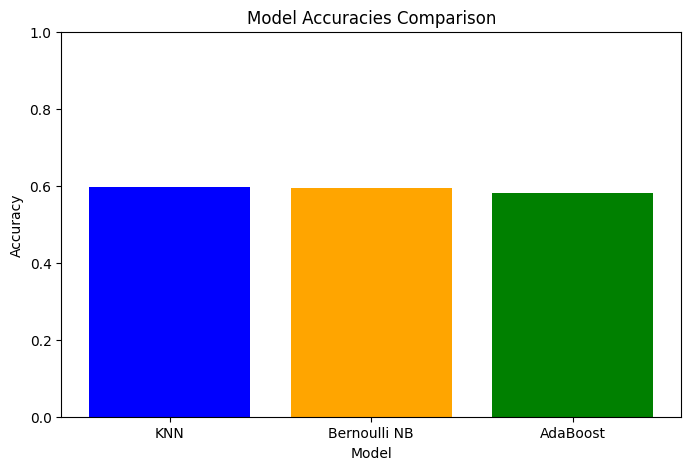

In [ ]:
# Plot accuracies of the three models
models = ['KNN', 'Bernoulli NB', 'AdaBoost']
accuracies = [accuracy, accuracy_nb, accuracy_ada]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['blue', 'orange', 'green'])
plt.title('Model Accuracies Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)  # Set y-axis limits between 0 and 1 for accuracy
plt.show()

#deze plot toont dat ze alle drie ongeveer dezelfde accuracy hebben